# Rossmann Store Sales — Dev A: Data, EDA and Time Series
**Course:** Cluster 10 · Forecasting & Open Data Analytics  **Dataset:** Kaggle *Rossmann Store Sales* (1,115 stores, ~1M store-days)

This notebook covers every task on the team board for **Dev A** and ends by publishing `data/clean.parquet` for Dev B.

| # | Section | Board task |
|---|---------|-----------|
| 0 | Setup and data download | – |
| 1 | Chunked CSV load, dtypes, Parquet, memory/size/time benchmark | Chunked CSV load with explicit dtypes and Parquet export |
| 2 | Merge with `store.csv`, descriptive stats, missing values, outliers | Merge train and store; descriptive stats, missing values, outliers |
| 3 | Time-index check (frequency, continuity, stores missing Jul–Dec 2014) | Time-index check |
| 4 | Resample (weekly/monthly) and rolling means | Resample and rolling means |
| 5 | MSTL decomposition (periods 7 and 365) | MSTL on total sales and 3–5 sample stores |
| 6 | Stationarity (ADF + KPSS) and ACF/PACF | Stationarity and ACF/PACF |
| 7 | Plots (interactive Plotly + static) | Plots |
| 8 | Publish `data/clean.parquet` + hand-off | Publish and hand over to Dev B |

**Run order:** Runtime → Run all. Only section 0 needs your input (upload `kaggle.json` or the two CSV files).

## 0. Setup

In [1]:
%pip install -q "statsmodels>=0.14" plotly pyarrow

In [2]:
import os, time, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

# Folder layout agreed in the team contract: data/ src/ notebooks/ outputs/ app/
DATA, RAW, OUT = Path("data"), Path("data/raw"), Path("outputs")
for p in (DATA, RAW, OUT):
    p.mkdir(parents=True, exist_ok=True)

HOLDOUT_START, HOLDOUT_END = "2015-06-20", "2015-07-31"   # last 42 days (used by Dev B, shaded here)
print("pandas", pd.__version__)

pandas 2.2.3


### Get the data
Choose one option and set `SOURCE`:
* `"kaggle"` – upload your `kaggle.json` (Kaggle → Settings → *Create New Token*). You must have clicked **Join Competition / accept rules** on the competition page once.
* `"upload"` – upload `train.csv` (or the zip, e.g. `train_csv.zip`) and `store.csv` yourself; zips are unpacked automatically. `test.csv` / `sample_submission.csv` are not needed.
* `"drive"` – read them from Google Drive (edit `DRIVE_DIR`).
* `"existing"` – files are already in `data/raw/`.

The external bundle (`store_states`, weather, Google Trends) belongs to Dev C and is not needed here.

In [5]:
SOURCE = "upload"                                  # "kaggle" | "upload" | "drive" | "existing"
DRIVE_DIR = "/content/drive/MyDrive/rossmann"      # only used when SOURCE == "drive"

if SOURCE == "kaggle":
    from google.colab import files
    files.upload()                                 # choose kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    os.system(f"kaggle competitions download -c rossmann-store-sales -p {RAW}")
    for z in RAW.glob("*.zip"):
        zipfile.ZipFile(z).extractall(RAW)
elif SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()                      # choose train.csv and store.csv
    for name in uploaded:
        shutil.move(name, RAW / name)
elif SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    for f in list(Path(DRIVE_DIR).glob("*.csv")) + list(Path(DRIVE_DIR).glob("*.zip")):
        shutil.copy(f, RAW / f.name)

# Kaggle gives train.csv as a zip (e.g. train_csv.zip) - unpack any zip so train.csv / store.csv exist
for z in RAW.glob("*.zip"):
    zipfile.ZipFile(z).extractall(RAW)

print(sorted(p.name for p in RAW.iterdir()))

Saving store.csv to store.csv
Saving train.csv.zip to train.csv.zip
['store.csv', 'train.csv', 'train.csv.zip']


## 1. Chunked CSV load, explicit dtypes and Parquet
`StateHoliday` mixes strings (`a`, `b`, `c`) and the integer `0`, which makes pandas infer an `object` column with mixed types. We force it to `str`, read the file in chunks with explicit dtypes, then store everything as Parquet and compare **file size, load time and RAM** against a naive `read_csv`.

In [6]:
RAW_TRAIN, RAW_STORE = RAW / "train.csv", RAW / "store.csv"
assert RAW_TRAIN.exists() and RAW_STORE.exists(), "train.csv / store.csv not found in data/raw - rerun the data cell above"

TRAIN_DTYPES = {
    "Store": "int16", "DayOfWeek": "int8", "Sales": "int32", "Customers": "int16",
    "Open": "int8", "Promo": "int8", "StateHoliday": "str", "SchoolHoliday": "int8",
}

def mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

def file_mb(path):
    return os.path.getsize(path) / 1024**2

def load_train_chunked(path, chunksize=200_000):
    """Read train.csv in chunks with explicit dtypes, then concatenate."""
    parts = []
    for chunk in pd.read_csv(path, dtype=TRAIN_DTYPES, parse_dates=["Date"], chunksize=chunksize):
        parts.append(chunk)
    out = pd.concat(parts, ignore_index=True)
    out["StateHoliday"] = out["StateHoliday"].astype("category")
    return out, len(parts)

# (a) naive load: pandas guesses everything, Date stays a string, StateHoliday is mixed
t0 = time.perf_counter()
naive = pd.read_csv(RAW_TRAIN, low_memory=False)
t_naive = time.perf_counter() - t0
mem_naive = mem_mb(naive)
del naive

# (b) chunked load with explicit dtypes
t0 = time.perf_counter()
train, n_chunks = load_train_chunked(RAW_TRAIN)
t_chunk = time.perf_counter() - t0

# (c) Parquet round trip
PQ_RAW = DATA / "train_raw.parquet"
t0 = time.perf_counter()
train.to_parquet(PQ_RAW, index=False)
t_write = time.perf_counter() - t0
t0 = time.perf_counter()
train_pq = pd.read_parquet(PQ_RAW)
t_pq = time.perf_counter() - t0

bench = pd.DataFrame(
    {
        "file_MB": [file_mb(RAW_TRAIN), file_mb(RAW_TRAIN), file_mb(PQ_RAW)],
        "load_s": [t_naive, t_chunk, t_pq],
        "memory_MB": [mem_naive, mem_mb(train), mem_mb(train_pq)],
    },
    index=["CSV - default read_csv", f"CSV - chunked ({n_chunks} chunks) + dtypes", "Parquet (snappy)"],
).round(2)
bench.to_csv(OUT / "load_benchmark.csv")
print(f"Parquet write time: {t_write:.2f}s")
display(bench)
print(train.dtypes)
print(train.shape, "| StateHoliday values:", sorted(train["StateHoliday"].unique()))
del train_pq

Parquet write time: 0.40s


,file_MB,load_s,memory_MB
CSV - default read_csv,36.29,0.85,160.06
CSV - chunked (6 chunks) + dtypes,36.29,4.40,20.37
Parquet (snappy),4.33,0.19,20.37


Store                     int16
DayOfWeek                  int8
Date             datetime64[ns]
Sales                     int32
Customers                 int16
Open                       int8
Promo                      int8
StateHoliday           category
SchoolHoliday              int8
dtype: object
(1017209, 9) | StateHoliday values: ['0', 'a', 'b', 'c']


## 2. Merge with `store.csv`, descriptive statistics, missing values, outliers

In [7]:
store = pd.read_csv(RAW_STORE)
for c in ["CompetitionOpenSinceMonth", "Promo2SinceWeek"]:
    store[c] = store[c].astype("Int8")
for c in ["CompetitionOpenSinceYear", "Promo2SinceYear"]:
    store[c] = store[c].astype("Int16")
store["Store"] = store["Store"].astype("int16")
store["CompetitionDistance"] = store["CompetitionDistance"].astype("float32")
store["Promo2"] = store["Promo2"].astype("int8")
for c in ["StoreType", "Assortment", "PromoInterval"]:
    store[c] = store[c].astype("category")

df = train.merge(store, on="Store", how="left", validate="m:1")
assert df["StoreType"].notna().all(), "some stores in train have no row in store.csv"

# StateHoliday: one clean categorical ("0" = none, a = public, b = Easter, c = Christmas)
df["StateHoliday"] = df["StateHoliday"].astype(str).replace({"0.0": "0"}).astype("category")
print(df.shape, f"| RAM {mem_mb(df):.0f} MB")
df.head()

(1017209, 18) | RAM 38 MB


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9,2008,0,<NA>,<NA>,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11,2007,1,13,2010,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12,2006,1,14,2011,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9,2009,0,<NA>,<NA>,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4,2015,0,<NA>,<NA>,NaN


In [8]:
# --- descriptive statistics --------------------------------------------------
display(df.select_dtypes("number").describe().T.round(2))
display(df.select_dtypes(["category", "object"]).describe().T)

print("\nSales distribution on OPEN days with Sales > 0:")
open_pos = (df["Open"] == 1) & (df["Sales"] > 0)
display(df.loc[open_pos, "Sales"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

# --- missing values ----------------------------------------------------------
missing = pd.DataFrame({"n_missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing = missing[missing["n_missing"] > 0]
print("\nMissing values in the merged table (all come from store.csv):")
display(missing)
print("Stores affected (store level):")
display(store.isna().sum()[lambda s: s > 0].to_frame("n_stores"))

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.429727,321.908651,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,3.998341,1.997391,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.818972,3849.926175,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.145946,464.411734,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.830107,0.375539,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.381515,0.485759,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.178647,0.383056,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.085449,7714.276367,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.222866,3.211832,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.690228,5.992644,1900.0,2006.0,2010.0,2013.0,2015.0


,count,unique,top,freq
StateHoliday,1017209,4,0,986159
StoreType,1017209,4,a,551627
Assortment,1017209,3,a,537445
PromoInterval,509178,3,"Jan,Apr,Jul,Oct",293122



Sales distribution on OPEN days with Sales > 0:


,Sales
count,844338.0
mean,6956.0
std,3104.0
min,46.0
1%,2188.0
5%,3174.0
25%,4859.0
50%,6369.0
75%,8360.0
95%,12668.0



Missing values in the merged table (all come from store.csv):


,n_missing,pct
CompetitionDistance,2642,0.26
CompetitionOpenSinceMonth,323348,31.79
CompetitionOpenSinceYear,323348,31.79
Promo2SinceWeek,508031,49.94
Promo2SinceYear,508031,49.94
PromoInterval,508031,49.94


Stores affected (store level):


,n_stores
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


In [9]:
# --- missing-value handling (documented, minimal) ----------------------------
# * CompetitionDistance: 3 stores -> median, with a flag so models can tell
# * Competition*/Promo2* "since" columns: NaN means "not applicable" -> kept as NaN (Dev B decides)
# * PromoInterval: NaN means "no Promo2" -> explicit "None"
df["CompetitionDistance_missing"] = df["CompetitionDistance"].isna()
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(store["CompetitionDistance"].median()).astype("float32")
df["PromoInterval"] = df["PromoInterval"].cat.add_categories("None").fillna("None")

# --- logical consistency: Open vs Sales --------------------------------------
closed_share = (df["Open"] == 0).mean()
df["open_zero_sales"] = (df["Open"] == 1) & (df["Sales"] == 0)     # open but no sales -> suspicious rows
closed_with_sales = ((df["Open"] == 0) & (df["Sales"] > 0)).sum()
print(f"Closed days (Open=0): {closed_share:.1%} of rows")          # board note: about 17%
print(f"Open=1 but Sales=0 : {df['open_zero_sales'].sum():,} rows (flagged in column open_zero_sales)")
print(f"Open=0 but Sales>0 : {closed_with_sales:,} rows")
print(f"Duplicate (Store, Date) keys: {df.duplicated(['Store', 'Date']).sum():,}")

# --- outliers: per-store IQR rule (k=3 = "extreme"), open days with sales only -
q = df.loc[open_pos].groupby("Store")["Sales"].quantile([0.25, 0.75]).unstack()
iqr = q[0.75] - q[0.25]
hi, lo = q[0.75] + 3 * iqr, q[0.25] - 3 * iqr
sales_open = df.loc[open_pos, "Sales"]
df["sales_outlier"] = False
df.loc[open_pos, "sales_outlier"] = (
    (sales_open > df.loc[open_pos, "Store"].map(hi)) | (sales_open < df.loc[open_pos, "Store"].map(lo))
)
print(f"\nExtreme sales outliers (3x IQR per store): {df['sales_outlier'].sum():,} rows "
      f"({df['sales_outlier'].mean():.3%}) - flagged, NOT removed")
display(df.loc[df["sales_outlier"]].nlargest(8, "Sales")[["Store", "Date", "Sales", "Promo", "StateHoliday", "StoreType"]])

Closed days (Open=0): 17.0% of rows
Open=1 but Sales=0 : 54 rows (flagged in column open_zero_sales)
Open=0 but Sales>0 : 0 rows
Duplicate (Store, Date) keys: 0

Extreme sales outliers (3x IQR per store): 1,113 rows (0.109%) - flagged, NOT removed


,Store,Date,Sales,Promo,StateHoliday,StoreType
44393,909,2015-06-22,41551,0,0,a
132946,262,2015-04-03,38722,1,b,b
101726,262,2015-05-01,38484,1,a,b
87231,262,2015-05-14,38367,0,a,b
424086,57,2014-06-16,38037,1,0,d
627220,261,2013-12-16,37646,1,0,d
444361,262,2014-05-29,37403,0,a,b
620531,262,2013-12-22,37376,0,0,b


## 3. Time-index check: frequency, continuity, stores missing Jul–Dec 2014

In [10]:
full_idx = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
dates_present = pd.DatetimeIndex(df["Date"].drop_duplicates().sort_values())

print(f"Date range : {full_idx[0].date()} -> {full_idx[-1].date()}  ({len(full_idx)} calendar days)")
print(f"Inferred frequency of the date index: {pd.infer_freq(dates_present)}")
print(f"Calendar days missing from the whole dataset: {len(full_idx.difference(dates_present))}")
print(f"Is the date axis sorted in the file? {df['Date'].is_monotonic_increasing} (we sort by Store, Date at the end)")

counts = df.groupby("Store")["Date"].agg(first="min", last="max", n_days="count")
counts["missing_days"] = len(full_idx) - counts["n_days"]
print(f"\nStores with a complete daily history: {(counts['missing_days'] == 0).sum()} / {len(counts)}")

incomplete = counts.index[counts["missing_days"] > 0]
rows = []
for s, g in df[df["Store"].isin(incomplete)].groupby("Store"):
    miss = full_idx.difference(pd.DatetimeIndex(g["Date"]))
    rows.append({"Store": s, "n_missing": len(miss), "gap_start": miss.min(), "gap_end": miss.max(),
                 "one_block": (miss.max() - miss.min()).days + 1 == len(miss)})
gaps = pd.DataFrame(rows)
gaps.to_csv(OUT / "stores_with_gaps.csv", index=False)
print(f"Stores with gaps: {len(gaps)}")
display(gaps.groupby(["gap_start", "gap_end", "n_missing", "one_block"]).size().rename("n_stores").reset_index())

df["has_gap"] = df["Store"].isin(incomplete)            # handy flag for Dev B / Dev C

# Weekday x open-days sanity check
display(df.groupby("DayOfWeek")["Open"].mean().round(3).rename("share_open").to_frame().T)

Date range : 2013-01-01 -> 2015-07-31  (942 calendar days)
Inferred frequency of the date index: D
Calendar days missing from the whole dataset: 0
Is the date axis sorted in the file? False (we sort by Store, Date at the end)

Stores with a complete daily history: 934 / 1115
Stores with gaps: 181


,gap_start,gap_end,n_missing,one_block,n_stores
0,2013-01-01,2013-01-01,1,True,1
1,2014-07-01,2014-12-31,184,True,180


DayOfWeek,1,2,3,4,5,6,7
share_open,0.95,0.988,0.974,0.923,0.951,0.995,0.025


### Daily aggregate series
Because ~180 stores have no rows from July to December 2014, the **total** daily sales has an artificial level drop in that window. We therefore keep two aggregates: *total sales* (the board requirement) and *sales per open store* (not affected by missing stores).

In [11]:
df["IsStateHoliday"] = (df["StateHoliday"] != "0").astype("int8")

daily = df.groupby("Date").agg(
    Sales=("Sales", "sum"),
    Customers=("Customers", "sum"),
    n_stores=("Store", "nunique"),
    n_open=("Open", "sum"),
    promo_share=("Promo", "mean"),
    school_share=("SchoolHoliday", "mean"),
    state_holiday_share=("IsStateHoliday", "mean"),
)
daily = daily.asfreq("D")                       # explicit daily frequency
assert daily["Sales"].notna().all(), "gap in the aggregated daily series"
daily["SalesPerOpenStore"] = daily["Sales"] / daily["n_open"].replace(0, np.nan)
daily.to_parquet(DATA / "daily_total.parquet")
daily.head()

,Sales,Customers,n_stores,n_open,promo_share,school_share,state_holiday_share,SalesPerOpenStore
Date,,,,,,,,
2013-01-01,97235,19491,1114,17,0.0,1.000000,1.0,5719.705882
2013-01-02,6949829,834075,1115,1111,0.0,1.000000,0.0,6255.471647
2013-01-03,6347820,761040,1115,1109,0.0,0.932735,0.0,5723.913436
2013-01-04,6638954,782137,1115,1108,0.0,0.932735,0.0,5991.835740
2013-01-05,5951593,687472,1115,1107,0.0,0.100448,0.0,5376.326107


## 4. Resample and rolling means

In [12]:
weekly = daily.resample("W-SUN").agg(
    Sales=("Sales", "sum"), Customers=("Customers", "sum"),
    SalesPerOpenStore=("SalesPerOpenStore", "mean"), n_days=("Sales", "size"),
)
monthly = daily.resample("MS").agg(
    Sales=("Sales", "sum"), Customers=("Customers", "sum"),
    SalesPerOpenStore=("SalesPerOpenStore", "mean"), n_days=("Sales", "size"),
)
weekly_full = weekly[weekly["n_days"] == 7]      # drop the partial first and last week
monthly_full = monthly[monthly["n_days"] >= 28]  # drop the partial last month (Jul 2015 is complete, Jan 2013 too)

for w in (7, 28):
    daily[f"Sales_ma{w}"] = daily["Sales"].rolling(w, center=True).mean()
    daily[f"SalesPerOpenStore_ma{w}"] = daily["SalesPerOpenStore"].rolling(w, center=True).mean()

fig = go.Figure()
fig.add_trace(go.Scatter(x=daily.index, y=daily["Sales"], name="Daily", line=dict(width=1), opacity=0.35))
fig.add_trace(go.Scatter(x=daily.index, y=daily["Sales_ma7"], name="7-day mean"))
fig.add_trace(go.Scatter(x=daily.index, y=daily["Sales_ma28"], name="28-day mean"))
fig.add_trace(go.Scatter(x=weekly_full.index, y=weekly_full["Sales"] / 7, name="Weekly mean per day", mode="lines+markers", marker=dict(size=3)))
fig.update_layout(title="Total daily sales with rolling means and weekly resample", yaxis_title="Sales (EUR)", hovermode="x unified")
fig.write_html(OUT / "fig_rolling_means.html")
fig.show()

display(monthly_full[["Sales", "SalesPerOpenStore"]].round(0).T.iloc[:, :12])

Date,2013-01-01,2013-02-01,2013-03-01,2013-04-01,2013-05-01,2013-06-01,2013-07-01,2013-08-01,2013-09-01,2013-10-01,2013-11-01,2013-12-01
Sales,180132207.0,171534275.0,201180369.0,183431432.0,185411063.0,180702351.0,208843882.0,198042727.0,178053963.0,187662330.0,196170924.0,231710561.0
SalesPerOpenStore,6405.0,6780.0,7467.0,6572.0,7225.0,6630.0,6991.0,6715.0,6465.0,6566.0,7446.0,9013.0


## 5. MSTL decomposition (periods 7 and 365)
MSTL (multiple seasonal-trend decomposition by LOESS) separates a **weekly** and a **yearly** seasonality. With ~2.6 years of data (942 days) the yearly period is only observed ~2.6 times, so treat the 365-day component as indicative.

In [13]:
def decompose(series, periods=(7, 365)):
    s = series.astype(float).asfreq("D")
    res = MSTL(s, periods=periods).fit()
    seasonal = pd.DataFrame(np.asarray(res.seasonal), index=s.index, columns=[f"seasonal_{p}" for p in periods])
    out = pd.concat([s.rename("observed"), pd.Series(np.asarray(res.trend), index=s.index, name="trend"),
                     seasonal, pd.Series(np.asarray(res.resid), index=s.index, name="resid")], axis=1)
    return out

def strengths(dec):
    """Wang-Smith-Hyndman strength of trend / seasonality in [0, 1]."""
    r = dec["resid"]
    res = {"trend": max(0, 1 - r.var() / (dec["trend"] + r).var())}
    for c in [c for c in dec if c.startswith("seasonal_")]:
        res[c] = max(0, 1 - r.var() / (dec[c] + r).var())
    return res

def plot_decomposition(dec, title):
    cols = list(dec.columns)
    fig = make_subplots(rows=len(cols), cols=1, shared_xaxes=True, vertical_spacing=0.03, subplot_titles=cols)
    for i, c in enumerate(cols, 1):
        fig.add_trace(go.Scatter(x=dec.index, y=dec[c], name=c, line=dict(width=1)), row=i, col=1)
    fig.update_layout(height=170 * len(cols) + 80, title=title, showlegend=False)
    return fig

# Sample stores: one "median" store per StoreType among stores with a complete history
full_hist = counts.index[counts["missing_days"] == 0]
store_mean = df[df["Store"].isin(full_hist) & (df["Open"] == 1)].groupby("Store")["Sales"].mean()
stype = store.set_index("Store")["StoreType"].astype(str)
SAMPLE_STORES = []
for t in ["a", "b", "c", "d"]:
    s = store_mean[stype.loc[store_mean.index] == t].sort_values()
    if len(s):
        SAMPLE_STORES.append(int(s.index[len(s) // 2]))
print("Sample stores:", SAMPLE_STORES, [stype[s] for s in SAMPLE_STORES])

series_for_mstl = {"Total sales (all stores)": daily["Sales"], "Sales per open store": daily["SalesPerOpenStore"].interpolate()}
for s in SAMPLE_STORES:
    series_for_mstl[f"Store {s} (type {stype[s]})"] = df[df["Store"] == s].set_index("Date")["Sales"]

decs, rows = {}, []
for name, ser in series_for_mstl.items():
    decs[name] = decompose(ser)
    rows.append({"series": name, **{k: round(v, 3) for k, v in strengths(decs[name]).items()}})
strength_table = pd.DataFrame(rows).set_index("series")
strength_table.to_csv(OUT / "mstl_strengths.csv")
display(strength_table)

Sample stores: [551, 769, 613, 960] ['a', 'b', 'c', 'd']


,trend,seasonal_7,seasonal_365
series,,,
Total sales (all stores),0.068,0.939,0.861
Sales per open store,0.231,0.833,0.897
Store 551 (type a),0.072,0.953,0.887
Store 769 (type b),0.871,0.736,0.906
Store 613 (type c),0.002,0.946,0.886
Store 960 (type d),0.101,0.923,0.857


In [14]:
for name in ["Total sales (all stores)", f"Store {SAMPLE_STORES[0]} (type {stype[SAMPLE_STORES[0]]})"]:
    fig = plot_decomposition(decs[name], f"MSTL decomposition - {name}")
    fig.write_html(OUT / f"fig_mstl_{name.split()[0].lower()}_{name.split()[1].strip('()').lower()}.html")
    fig.show()

## 6. Stationarity (ADF + KPSS) and ACF/PACF
* **ADF** – H0: unit root (non-stationary). Small p-value → reject → looks stationary.
* **KPSS** – H0: stationary. Small p-value → reject → looks non-stationary.
* Reading both together is safer than either alone.

In [15]:
def stationarity_report(x, name):
    x = pd.Series(x).dropna().astype(float)
    adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(x, regression="c", nlags="auto")[:2]
    adf_ok, kpss_ok = adf_p < 0.05, kpss_p >= 0.05          # True = "looks stationary"
    verdict = {(True, True): "stationary",
               (False, False): "non-stationary (difference it)",
               (True, False): "trend/seasonal structure - difference or detrend",
               (False, True): "inconclusive (low power)"}[(adf_ok, kpss_ok)]
    return {"series": name, "n": len(x), "ADF stat": round(adf_stat, 2), "ADF p": round(adf_p, 4),
            "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 4), "verdict": verdict}

tests = {
    "Total daily sales": daily["Sales"],
    "Total daily sales - seasonal diff (lag 7)": daily["Sales"].diff(7),
    "Sales per open store (daily)": daily["SalesPerOpenStore"].interpolate(),
    "Sales per open store - seasonal diff (lag 7)": daily["SalesPerOpenStore"].interpolate().diff(7),
    "Total weekly sales (full weeks)": weekly_full["Sales"],
    "Total weekly sales - first diff": weekly_full["Sales"].diff(),
}
for s in SAMPLE_STORES:
    tests[f"Store {s} daily sales"] = df[df["Store"] == s].set_index("Date")["Sales"]

stationarity = pd.DataFrame([stationarity_report(v, k) for k, v in tests.items()]).set_index("series")
stationarity.to_csv(OUT / "stationarity_tests.csv")
display(stationarity)

,n,ADF stat,ADF p,KPSS stat,KPSS p,verdict
series,,,,,,
Total daily sales,942,-4.76,0.0001,0.205,0.1000,stationary
Total daily sales - seasonal diff (lag 7),935,-12.85,0.0000,0.007,0.1000,stationary
Sales per open store (daily),942,-5.42,0.0000,1.018,0.0100,trend/seasonal structure - difference or detrend
Sales per open store - seasonal diff (lag 7),935,-10.30,0.0000,0.011,0.1000,stationary
Total weekly sales (full weeks),133,-3.79,0.0030,0.149,0.1000,stationary
Total weekly sales - first diff,132,-8.23,0.0000,0.028,0.1000,stationary
Store 551 daily sales,942,-8.08,0.0000,0.570,0.0258,trend/seasonal structure - difference or detrend
Store 769 daily sales,942,-1.96,0.3031,4.085,0.0100,non-stationary (difference it)
Store 613 daily sales,942,-4.33,0.0004,0.106,0.1000,stationary


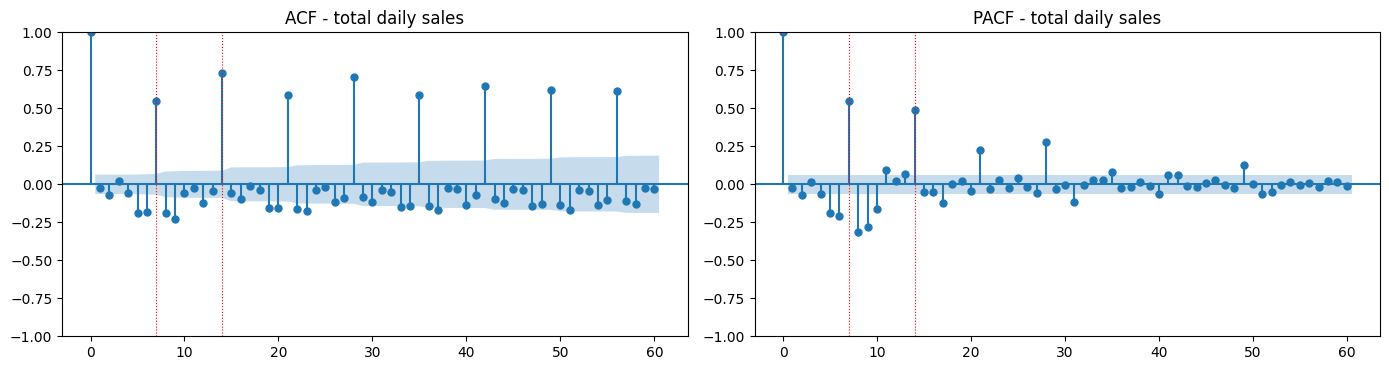

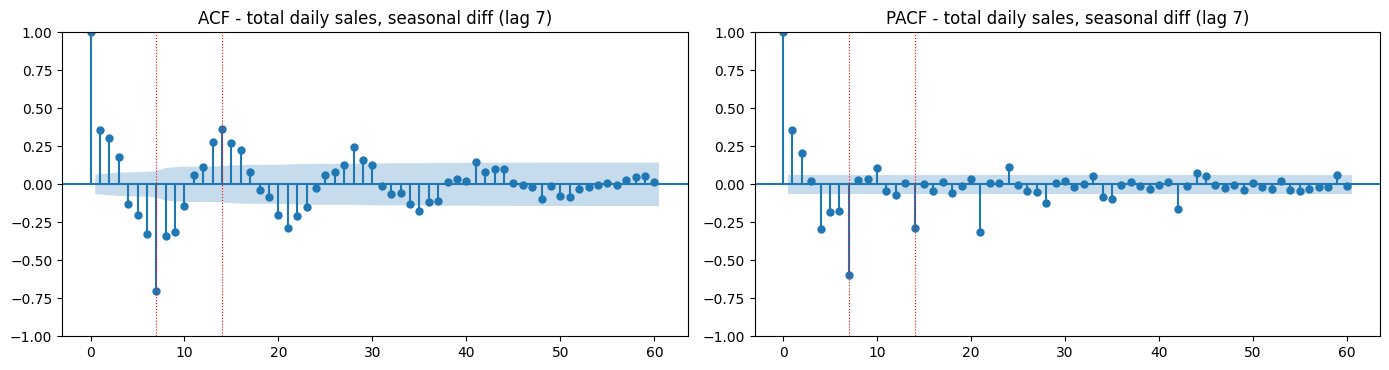

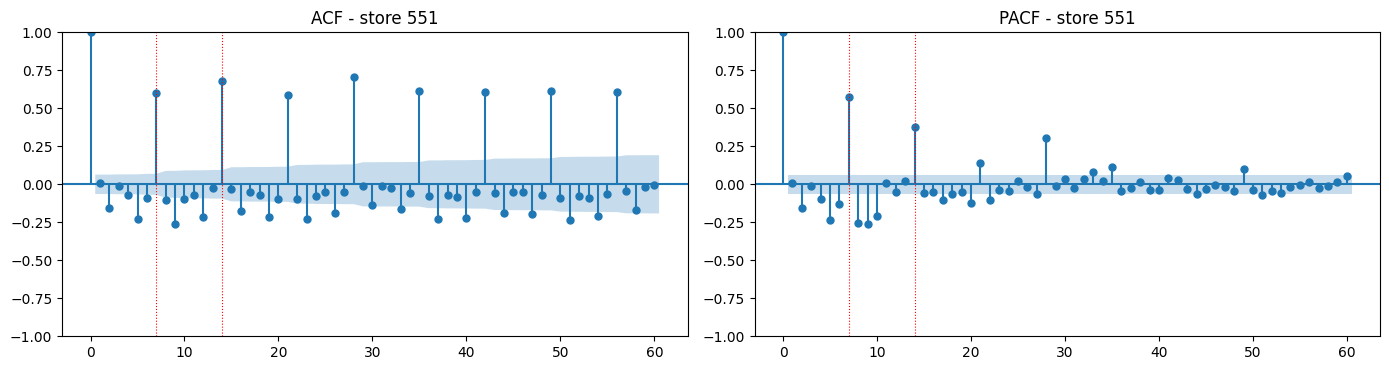

In [16]:
def acf_pacf(series, name, lags=60):
    x = series.dropna().astype(float)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    plot_acf(x, lags=lags, ax=ax[0], title=f"ACF - {name}")
    plot_pacf(x, lags=lags, ax=ax[1], title=f"PACF - {name}", method="ywm")
    for a in ax:
        a.axvline(7, color="red", ls=":", lw=0.8); a.axvline(14, color="red", ls=":", lw=0.8)
    plt.tight_layout()
    return fig

fig_acf = acf_pacf(daily["Sales"], "total daily sales")
fig_acf.savefig(OUT / "fig_acf_pacf_total.png", bbox_inches="tight"); plt.show()

fig_acf7 = acf_pacf(daily["Sales"].diff(7), "total daily sales, seasonal diff (lag 7)")
fig_acf7.savefig(OUT / "fig_acf_pacf_total_diff7.png", bbox_inches="tight"); plt.show()

s0 = SAMPLE_STORES[0]
fig_acf_s = acf_pacf(df[df["Store"] == s0].set_index("Date")["Sales"], f"store {s0}")
fig_acf_s.savefig(OUT / f"fig_acf_pacf_store{s0}.png", bbox_inches="tight"); plt.show()

## 7. Visualisations
Besides the rolling-mean chart (section 4) and MSTL plots (section 5) we add:
1. **Interactive total sales** with promo share and state-holiday shading (+ hold-out window)
2. Average sales by weekday × promo
3. Sales distribution by StoreType
4. Stores reporting per day (shows the Jul–Dec 2014 gap)

In [17]:
# 1) Interactive total sales with promo share and holiday shading
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=daily.index, y=daily["Sales"], name="Total sales", line=dict(width=1.2)), secondary_y=False)
fig.add_trace(go.Scatter(x=daily.index, y=daily["promo_share"], name="Share of stores on promo",
                         fill="tozeroy", line=dict(width=0.5, color="orange"), opacity=0.25), secondary_y=True)
holiday_days = daily.index[daily["state_holiday_share"] > 0.5]
for d in holiday_days:
    fig.add_vrect(x0=d, x1=d + pd.Timedelta(days=1), fillcolor="red", opacity=0.35, line_width=0, layer="below")
fig.add_vrect(x0=HOLDOUT_START, x1=HOLDOUT_END, fillcolor="green", opacity=0.12, line_width=0, layer="below",
              annotation_text="hold-out (last 42 days)", annotation_position="top left")
fig.update_layout(title=f"Total daily sales - promo share (orange) and state holidays (red, {len(holiday_days)} days)",
                  hovermode="x unified", height=520)
fig.update_yaxes(title_text="Sales (EUR)", secondary_y=False)
fig.update_yaxes(title_text="Promo share", range=[0, 1], secondary_y=True)
fig.update_xaxes(rangeslider_visible=True)
fig.write_html(OUT / "fig_total_sales_promo_holidays.html")
fig.show()

In [18]:
# 2) Average sales by weekday and promo (open days)
wd = df[df["Open"] == 1].groupby(["DayOfWeek", "Promo"], observed=True)["Sales"].mean().reset_index()
wd["Promo"] = wd["Promo"].map({0: "No promo", 1: "Promo"})
fig = px.bar(wd, x="DayOfWeek", y="Sales", color="Promo", barmode="group",
             labels={"DayOfWeek": "Day of week (1 = Monday)", "Sales": "Mean sales per open store-day"},
             title="Mean sales by weekday and promo (open days)")
fig.write_html(OUT / "fig_weekday_promo.html"); fig.show()

# 3) Sales distribution by StoreType (random sample for speed)
pool = df[(df["Open"] == 1) & (df["Sales"] > 0)]
smp = pool.sample(min(100_000, len(pool)), random_state=42)
fig = px.box(smp, x="StoreType", y="Sales", color="StoreType", points=False,
             category_orders={"StoreType": ["a", "b", "c", "d"]}, title="Sales distribution by StoreType (100k open store-days)")
fig.write_html(OUT / "fig_sales_by_storetype.html"); fig.show()

# 4) Stores reporting per day
fig = px.line(daily.reset_index(), x="Date", y="n_stores", title="Number of stores with data per day")
fig.update_yaxes(range=[0, 1200]); fig.write_html(OUT / "fig_stores_per_day.html"); fig.show()

## 8. Publish `data/clean.parquet` and hand over to Dev B
We keep **all** rows (closed days included, no imputation of the missing Jul–Dec 2014 days) and only add flags, so Dev B decides how to train/evaluate (e.g. open days only, drop `Sales == 0`).

| Column | Type | Note |
|---|---|---|
| `Store`, `Date`, `DayOfWeek` | int16 / datetime64 / int8 | key = (`Store`, `Date`), sorted |
| `Sales`, `Customers`, `Open`, `Promo`, `SchoolHoliday` | int32 / int16 / int8 | as in Kaggle |
| `StateHoliday` | category | `0`, `a`, `b`, `c` (all strings) |
| `StoreType`, `Assortment`, `PromoInterval` | category | from `store.csv` (`PromoInterval` NaN → `"None"`) |
| `CompetitionDistance` | float32 | 3 missing → median, see `CompetitionDistance_missing` |
| `CompetitionOpenSince*`, `Promo2`, `Promo2Since*` | Int / int8 | NaN kept where not applicable |
| `IsStateHoliday` | int8 | 1 if `StateHoliday != "0"` |
| `open_zero_sales`, `sales_outlier`, `has_gap`, `CompetitionDistance_missing` | bool | data-quality flags (rows are **not** dropped) |

In [19]:
CLEAN_PATH = DATA / "clean.parquet"
clean = df.sort_values(["Store", "Date"]).reset_index(drop=True)
for c in ["StoreType", "Assortment", "PromoInterval", "StateHoliday"]:
    clean[c] = clean[c].astype("category")
clean.to_parquet(CLEAN_PATH, index=False)

# --- validate by reading it back (what Dev B will do) ---------------------------
chk = pd.read_parquet(CLEAN_PATH)
assert not chk.duplicated(["Store", "Date"]).any()
assert chk["Date"].min() == pd.Timestamp("2013-01-01") and chk["Date"].max() == pd.Timestamp("2015-07-31")
assert chk["Store"].nunique() == 1115
assert chk[["Sales", "Open", "Promo", "StoreType"]].notna().all().all()
print(f"clean.parquet: {chk.shape[0]:,} rows x {chk.shape[1]} columns | {file_mb(CLEAN_PATH):.1f} MB on disk | {mem_mb(chk):.0f} MB in RAM")
print(chk.dtypes.to_string())
chk.head(3)

clean.parquet: 1,017,209 rows x 23 columns | 3.8 MB on disk | 43 MB in RAM
Store                                   int16
DayOfWeek                                int8
Date                           datetime64[ns]
Sales                                   int32
Customers                               int16
Open                                     int8
Promo                                    int8
StateHoliday                         category
SchoolHoliday                            int8
StoreType                            category
Assortment                           category
CompetitionDistance                   float32
CompetitionOpenSinceMonth                Int8
CompetitionOpenSinceYear                Int16
Promo2                                   int8
Promo2SinceWeek                          Int8
Promo2SinceYear                         Int16
PromoInterval                        category
CompetitionDistance_missing              bool
open_zero_sales                          bool
sales

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistance_missing,open_zero_sales,sales_outlier,has_gap,IsStateHoliday
0,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9,2008,0,<NA>,<NA>,None,False,False,False,False,1
1,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9,2008,0,<NA>,<NA>,None,False,False,False,False,0
2,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9,2008,0,<NA>,<NA>,None,False,False,False,False,0


In [20]:
# Key numbers for the report
print("=== Facts for the report (Dev A) ===")
print(f"Rows: {len(clean):,} | stores: {clean['Store'].nunique()} | {clean['Date'].min().date()} -> {clean['Date'].max().date()}")
print(f"Closed days: {closed_share:.1%} | Open=1 & Sales=0: {int(clean['open_zero_sales'].sum())} | extreme outliers: {int(clean['sales_outlier'].sum())}")
print(f"Stores with gaps: {len(gaps)} (e.g. missing {gaps['n_missing'].mode().iat[0]} days each)")
print("CSV vs Parquet:"); display(bench)
print("Seasonality strength (total sales):", strength_table.loc["Total sales (all stores)"].to_dict())
print("Handed over: data/clean.parquet, data/daily_total.parquet, outputs/*.html|png|csv")

=== Facts for the report (Dev A) ===
Rows: 1,017,209 | stores: 1115 | 2013-01-01 -> 2015-07-31
Closed days: 17.0% | Open=1 & Sales=0: 54 | extreme outliers: 1113
Stores with gaps: 181 (e.g. missing 184 days each)
CSV vs Parquet:


,file_MB,load_s,memory_MB
CSV - default read_csv,36.29,0.85,160.06
CSV - chunked (6 chunks) + dtypes,36.29,4.40,20.37
Parquet (snappy),4.33,0.19,20.37


Seasonality strength (total sales): {'trend': 0.068, 'seasonal_7': 0.939, 'seasonal_365': 0.861}
Handed over: data/clean.parquet, data/daily_total.parquet, outputs/*.html|png|csv


In [21]:
# Package everything for the team (download as zip and/or copy to Drive)
ZIP_AND_DOWNLOAD = True
COPY_TO_DRIVE = False
DRIVE_TARGET = "/content/drive/MyDrive/rossmann"

pkg = Path("devA_handoff"); shutil.rmtree(pkg, ignore_errors=True); (pkg / "data").mkdir(parents=True)
shutil.copy(CLEAN_PATH, pkg / "data"); shutil.copy(DATA / "daily_total.parquet", pkg / "data")
shutil.copytree(OUT, pkg / "outputs")
archive = shutil.make_archive("devA_handoff", "zip", pkg)
print("Created", archive, f"({file_mb(archive):.1f} MB)")

if COPY_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(pkg, DRIVE_TARGET, dirs_exist_ok=True)
    print("Copied to", DRIVE_TARGET)
if ZIP_AND_DOWNLOAD:
    from google.colab import files
    files.download(archive)

Created /content/devA_handoff.zip (12.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Dev A checklist
- [x] Chunked CSV load with explicit dtypes and Parquet export (CSV vs Parquet: size, memory, load time)
- [x] Merge train + store; descriptive stats, missing values, outliers (flag `Open=1 & Sales=0`, closed ≈ 17 %)
- [x] Time-index check: frequency, continuity, stores missing Jul–Dec 2014
- [x] Resample (weekly/monthly) and rolling means
- [x] MSTL (7 and 365) on total sales and sample stores
- [x] ADF + KPSS and ACF/PACF
- [x] Plots: interactive Plotly total sales with promo/holiday shading, MSTL components, ACF/PACF
- [x] `data/clean.parquet` published → **Dev B can start feature engineering**

**Interpretation notes to write in your own words for the defense:** why the total series drops in Jul–Dec 2014 (missing stores), why weekly seasonality dominates (Sundays closed), what ADF vs KPSS say before/after seasonal differencing, and why the lag-7 spike in the ACF motivates the seasonal-naive baseline.